# Preprocessing

**1. Data Collection**

In [1]:
import pandas as pd

dataset = pd.read_csv("Advertising.csv")
print("Original records:", len(dataset))
display(dataset.head())

Original records: 200


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


**2. Data Cleaning**

In [2]:
dataset = dataset.drop("Unnamed: 0", axis=1)

print("Missing values per column")
print(dataset.isna().sum())

print("Negative values per column")
print((dataset < 0).sum())

print("duplicate records:", dataset.duplicated().sum())


Missing values per column
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
Negative values per column
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
duplicate records: 0


**Detecting and Removing outliers**

In [3]:
features = ["TV", "Radio", "Newspaper"]
outlier_tables = []

for column in features:
    q1 = dataset[column].quantile(0.25)
    q3 = dataset[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    column_outliers = dataset[
        (dataset[column] < (lower)) | (dataset[column] > upper)
    ]

    print(column)
    print("Lower bound:", round(lower, 3))
    print("Upper bound:", round(upper, 3))
    print("Outliers:", len(column_outliers))
    outlier_tables.append(column_outliers)

outliers = pd.concat(outlier_tables).drop_duplicates()
cleaned = dataset.drop(outliers.index)

display(outliers)
print("Records removed:", len(outliers))
print("Records remaining:", len(cleaned))

TV
Lower bound: -142.3
Upper bound: 435.5
Outliers: 0
Radio
Lower bound: -29.85
Upper bound: 76.35
Outliers: 0
Newspaper
Lower bound: -35.775
Upper bound: 93.625
Outliers: 2


,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


Records removed: 2
Records remaining: 198


**3. Treating the Categorical Variables**

In [4]:
print(cleaned.dtypes)

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


**4. Splitting the Dataset**

In [5]:
from sklearn.model_selection import train_test_split

X = cleaned[["TV", "Radio", "Newspaper"]]
y = cleaned["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 158
Test records: 40


**5. Featuring the Dataset**

In [6]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

display(pd.DataFrame(X_train_scaled, columns=features).head().round(3))

,TV,Radio,Newspaper
0,0.427,1.392,-1.352
1,-1.626,1.725,2.155
2,-0.104,-0.566,-0.945
3,-0.872,-0.400,-0.816
4,-1.436,-0.799,-0.012


# Regression Model

**Simple Linear Regression**

In [7]:
from sklearn.linear_model import LinearRegression

simple_model = LinearRegression()
simple_model.fit(X_train[["TV"]], y_train)

simple_predictions = simple_model.predict(X_test[["TV"]])

**Multiple Linear Regression**

In [8]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

**Polynomial Regression (Degree 2)**

In [9]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_features = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = polynomial_features.fit_transform(X_train)
X_test_poly = polynomial_features.transform(X_test)

polynomial_model = LinearRegression()
polynomial_model.fit(X_train_poly, y_train)

polynomial_predictions = polynomial_model.predict(X_test_poly)

**Ridge, Lasso, and Elastic Net Regression**

In [10]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

ridge_model = Ridge()
ridge_model.fit(X_train_scaled, y_train)
ridge_predictions = ridge_model.predict(X_test_scaled)

lasso_model = Lasso()
lasso_model.fit(X_train_scaled, y_train)
lasso_predictions = lasso_model.predict(X_test_scaled)

elastic_net_model = ElasticNet()
elastic_net_model.fit(X_train_scaled, y_train)
elastic_net_predictions = elastic_net_model.predict(X_test_scaled)

**Comparing the Models**

In [11]:
from sklearn.metrics import mean_squared_error, r2_score

predictions = {
    "Simple Linear Regression": simple_predictions,
    "Multiple Linear Regression": multiple_predictions,
    "Polynomial Regression (Degree 2)": polynomial_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions,
    "Elastic Net Regression": elastic_net_predictions
}

results = []
for name, predicted_sales in predictions.items():
    r_squared = r2_score(y_test, predicted_sales)
    mse = mean_squared_error(y_test, predicted_sales)
    results.append([name, r_squared, mse])

model_comparison = pd.DataFrame(results, columns=["Model", "R-squared", "MSE"])
display(model_comparison.round(4))

best_row = model_comparison["R-squared"].idxmax()
print("Best-fitting model:", model_comparison.loc[best_row, "Model"])

,Model,R-squared,MSE
0,Simple Linear Regression,0.6116,10.5355
1,Multiple Linear Regression,0.8989,2.7409
2,Polynomial Regression (Degree 2),0.9875,0.3399
3,Ridge Regression,0.8980,2.7670
4,Lasso Regression,0.8110,5.1273
5,Elastic Net Regression,0.7169,7.6788


Best-fitting model: Polynomial Regression (Degree 2)


**Observed and Predicted Sales**

In [12]:
sales_comparison = pd.DataFrame({
    "CSV record": y_test.index + 1,
    "Observed Sales": y_test.to_numpy(),
    "Simple prediction": simple_predictions,
    "Multiple prediction": multiple_predictions,
    "Polynomial prediction": polynomial_predictions,
    "Ridge prediction": ridge_predictions,
    "Lasso prediction": lasso_predictions,
    "Elastic Net prediction": elastic_net_predictions
})
sales_comparison["Polynomial error"] = (
    sales_comparison["Observed Sales"] - sales_comparison["Polynomial prediction"]
)

display(sales_comparison.round(2))

,CSV record,Observed Sales,Simple prediction,Multiple prediction,Polynomial prediction,Ridge prediction,Lasso prediction,Elastic Net prediction,Polynomial error
0,67,9.5,8.55,8.90,7.86,8.92,10.24,10.94,1.64
1,117,12.2,13.61,12.01,12.81,12.02,12.66,12.87,-0.61
2,18,24.4,20.28,23.21,24.11,23.16,20.60,19.43,0.29
3,144,10.4,11.98,8.92,10.25,8.96,10.43,11.10,0.15
4,159,7.3,7.63,10.47,7.71,10.49,11.06,11.89,-0.41
5,129,24.7,17.41,21.90,24.20,21.83,19.66,18.51,0.50
6,143,20.1,17.42,19.20,20.16,19.17,17.74,17.05,-0.06
7,32,11.9,12.37,11.45,12.36,11.47,12.14,12.55,-0.46
8,20,14.6,13.99,14.10,14.88,14.09,14.11,14.05,-0.28
9,170,15.0,20.41,17.80,14.49,17.77,17.17,16.28,0.51


**Intercept and Coefficients**

In [13]:

print(f"Intercept: {polynomial_model.intercept_:.17g}")

terms = polynomial_features.get_feature_names_out()

coefficients = pd.DataFrame({
    "Term": ["Intercept", *terms],
    "Coefficient": [polynomial_model.intercept_, *polynomial_model.coef_],
})

display(coefficients.style.format({"Coefficient": "{:.10f}"}))

Intercept: 4.7779881145067868


,Term,Coefficient
0,Intercept,4.7779881145
1,TV,0.0528026523
2,Radio,0.0264464686
3,Newspaper,0.0220145058
4,TV^2,-0.0001101773
5,TV Radio,0.0011018846
6,TV Newspaper,-0.0000762860
7,Radio^2,-0.0000409928
8,Radio Newspaper,0.0001624866
9,Newspaper^2,-0.0001448088


**Random Selection of Test Records**

In [14]:
test_records = cleaned.loc[X_test.index]
selected_records = test_records.sample(n=5, replace=False, random_state=361277)

selected_records.insert(0, "CSV record", selected_records.index + 1)
display(selected_records.set_index("CSV record"))

,TV,Radio,Newspaper,Sales
CSV record,,,,
62,261.3,42.7,54.7,24.2
98,184.9,21.0,22.0,15.5
143,220.5,33.2,37.9,20.1
150,44.7,25.8,20.6,10.1
117,139.2,14.3,25.6,12.2


# Classification Model

In [15]:
sales_cutoff = y_train.median()

y_train_class = (y_train >= sales_cutoff).astype(int)
y_test_class = (y_test >= sales_cutoff).astype(int)

print("Training sales median:", sales_cutoff)

Training sales median: 12.9


**Building and Comparing Classification Models (6 points)**

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

classifiers = {
    "Logistic Regression": LogisticRegression(random_state=0),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(criterion="entropy", random_state=0),
    "Support Vector Machine": SVC(kernel="rbf"),
"Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
"Gradient Boosting": GradientBoostingClassifier(random_state=42),
    
}




scores = []

for name, classifier in classifiers.items():
    classifier.fit(X_train_scaled, y_train_class)
    predicted_class = classifier.predict(X_test_scaled)

    matrix = confusion_matrix(y_test_class, predicted_class, labels=[0, 1])
    errors = matrix[0, 1] + matrix[1, 0]
    accuracy = accuracy_score(y_test_class, predicted_class)
    precision = precision_score(y_test_class, predicted_class, zero_division=0)
    recall = recall_score(y_test_class, predicted_class, zero_division=0)
    f1 = f1_score(y_test_class, predicted_class, zero_division=0)
    scores.append([name, matrix.tolist(), errors, accuracy, precision, recall, f1])

classifier_comparison = pd.DataFrame(
    scores,
    columns=["Classifier", "Confusion Matrix", "Errors (FP + FN)", "Accuracy",
             "Precision", "Recall", "F1-score"]
)
classifier_comparison = classifier_comparison.sort_values(
    ["Accuracy", "F1-score"], ascending=False
).reset_index(drop=True)

print("Test Set Classification Results")
display(classifier_comparison.round(4))

best_classifier_name = classifier_comparison.iloc[0]["Classifier"]
best_classifier = classifiers[best_classifier_name]
print("Best-fit classifier:", best_classifier_name)

Test Set Classification Results


,Classifier,Confusion Matrix,Errors (FP + FN),Accuracy,Precision,Recall,F1-score
0,KNN,"[[19, 2], [0, 19]]",2,0.950,0.9048,1.0000,0.9500
1,Support Vector Machine,"[[19, 2], [0, 19]]",2,0.950,0.9048,1.0000,0.9500
2,Gradient Boosting,"[[20, 1], [1, 18]]",2,0.950,0.9474,0.9474,0.9474
3,Logistic Regression,"[[19, 2], [1, 18]]",3,0.925,0.9000,0.9474,0.9231
4,Decision Tree,"[[19, 2], [1, 18]]",3,0.925,0.9000,0.9474,0.9231
5,Random Forest,"[[19, 2], [1, 18]]",3,0.925,0.9000,0.9474,0.9231
6,Gaussian Naive Bayes,"[[20, 1], [3, 16]]",4,0.900,0.9412,0.8421,0.8889


Best-fit classifier: KNN


In [17]:
best_test_classes = best_classifier.predict(X_test_scaled)
category_names = {0: "Low Sales", 1: "High Sales"}

test_results = X_test.copy()
test_results.insert(0, "CSV record", test_results.index + 1)
test_results["Observed category"] = y_test_class.map(category_names)

for name, classifier in classifiers.items():
    predicted_classes = classifier.predict(X_test_scaled)
    test_results[name] = [category_names[label] for label in predicted_classes]

display(test_results.set_index("CSV record"))
test_results.set_index("CSV record").to_clipboard(excel=True)

,TV,Radio,Newspaper,Observed category,Logistic Regression,KNN,Gaussian Naive Bayes,Decision Tree,Support Vector Machine,Random Forest,Gradient Boosting
CSV record,,,,,,,,,,,
67,31.5,24.6,2.2,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales
117,139.2,14.3,25.6,Low Sales,Low Sales,Low Sales,Low Sales,High Sales,Low Sales,High Sales,Low Sales
18,281.4,39.6,55.8,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales
144,104.6,5.7,34.4,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales
159,11.7,36.9,45.2,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales,Low Sales
129,220.3,49.0,3.2,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales
143,220.5,33.2,37.9,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales
32,112.9,17.4,38.6,Low Sales,Low Sales,Low Sales,Low Sales,High Sales,Low Sales,Low Sales,High Sales
20,147.3,23.9,19.1,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales,High Sales


**Number of Elements in Each Target Category (1 point)**

In [18]:
actual_all_classes = (y >= sales_cutoff).astype(int)
all_predicted_classes = best_classifier.predict(sc.transform(X))

class_counts = pd.DataFrame({
    "Actual (all records)": actual_all_classes.value_counts(),
    "Predicted (all records)": pd.Series(all_predicted_classes).value_counts(),
    "Actual (test set)": y_test_class.value_counts(),
    "Predicted (test set)": pd.Series(best_test_classes).value_counts(),
}).reindex([0, 1]).fillna(0).astype(int)

class_counts.index = ["Low Sales", "High Sales"]
class_counts.index.name = "Category"
display(class_counts)

,Actual (all records),Predicted (all records),Actual (test set),Predicted (test set)
Category,,,,
Low Sales,97,99,21,19
High Sales,101,99,19,21


# Cluster Analysis

**K-Means and Elbow**

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

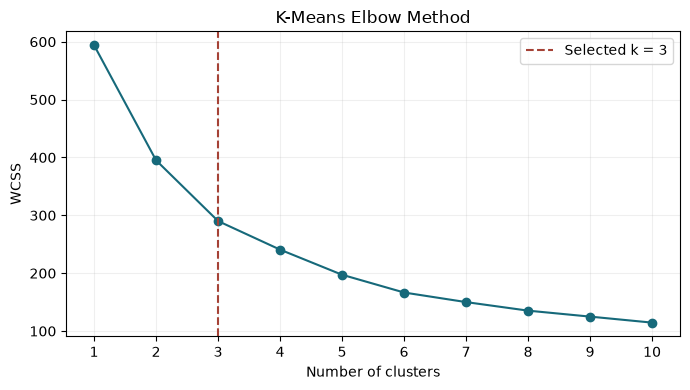

In [19]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

cluster_scaler = StandardScaler()
cluster_features = cluster_scaler.fit_transform(cleaned[features])

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    kmeans.fit(cluster_features)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, marker="o", color="#16697a")
plt.axvline(3, color="#a54236", linestyle="--", label="Selected k = 3")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
kmeans_data = cleaned.copy()
kmeans_data["Cluster"] = kmeans.fit_predict(cluster_features) + 1

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


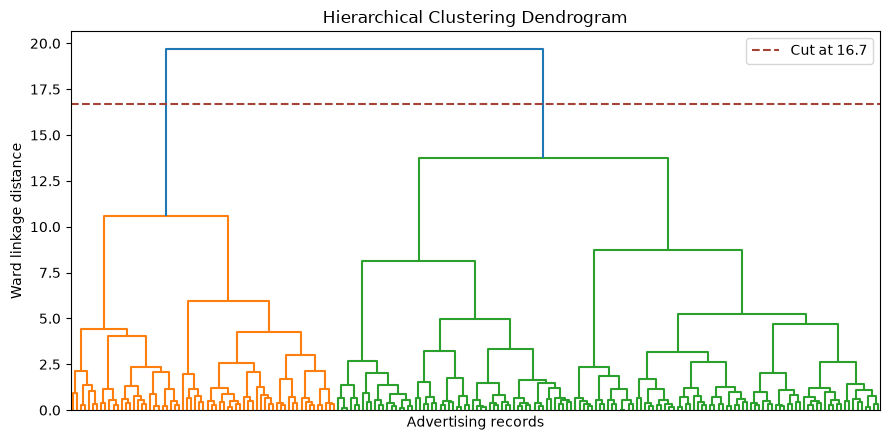

In [21]:
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

ward_links = sch.linkage(cluster_features, method="ward")
cut_height = 16.7

plt.figure(figsize=(9, 4.5))
sch.dendrogram(ward_links, no_labels=True, color_threshold=cut_height)
plt.axhline(cut_height, color="#a54236", linestyle="--", label="Cut at 16.7")
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Advertising records")
plt.ylabel("Ward linkage distance")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
hierarchical = AgglomerativeClustering(n_clusters=2, metric="euclidean", linkage="ward")
hierarchical_data = cleaned.copy()
hierarchical_data["Cluster"] = hierarchical.fit_predict(cluster_features) + 1

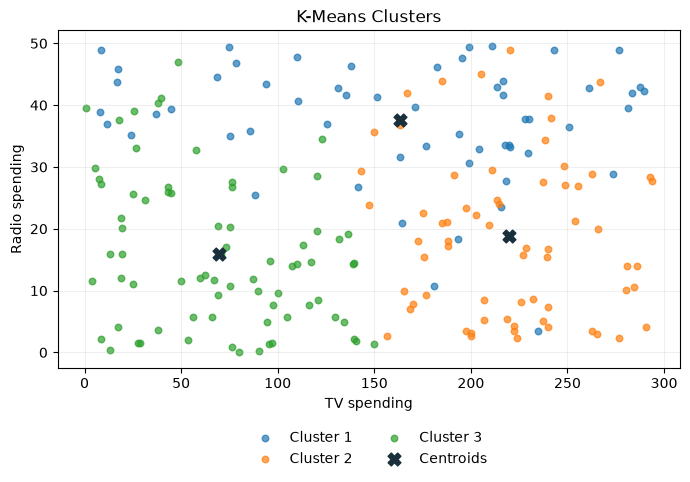

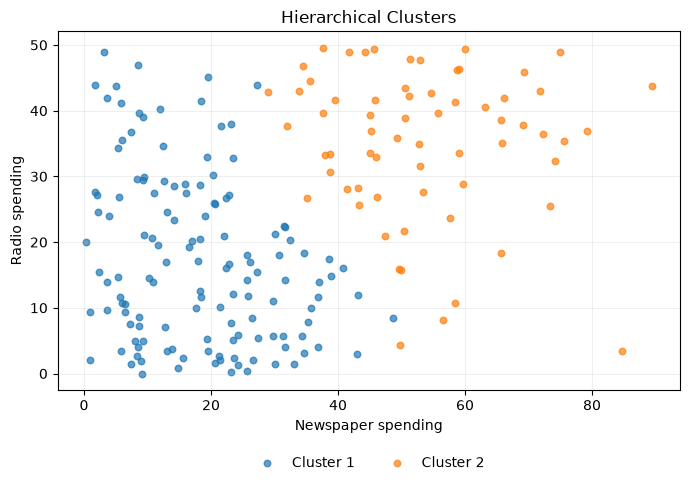

In [23]:
plt.figure(figsize=(7, 5))

for number in range(1, 4):
    records = kmeans_data[kmeans_data["Cluster"] == number]
    plt.scatter(records["TV"], records["Radio"], s=22, alpha=0.7,
                label=f"Cluster {number}")

centers = cluster_scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], marker="X", color="#192f3c",
            s=85, label="Centroids")

plt.title("K-Means Clusters")
plt.xlabel("TV spending")
plt.ylabel("Radio spending")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

for number in range(1, 3):
    records = hierarchical_data[hierarchical_data["Cluster"] == number]
    plt.scatter(records["Newspaper"], records["Radio"], s=22, alpha=0.7,
                label=f"Cluster {number}")

plt.title("Hierarchical Clusters")
plt.xlabel("Newspaper spending")
plt.ylabel("Radio spending")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Strategy Formulation**

In [24]:
profile_columns = ["TV", "Radio", "Newspaper", "Sales"]

kmeans_groups = kmeans_data.groupby("Cluster")
kmeans_profiles = kmeans_groups[profile_columns].mean()
kmeans_profiles.insert(0, "Records", kmeans_groups.size())
print("K-Means Profiles")
display(kmeans_profiles.round(2))

hierarchical_groups = hierarchical_data.groupby("Cluster")
hierarchical_profiles = hierarchical_groups[profile_columns].mean()
hierarchical_profiles.insert(0, "Records", hierarchical_groups.size())
print("Hierarchical Profiles")
display(hierarchical_profiles.round(2))

K-Means Profiles


,Records,TV,Radio,Newspaper,Sales
Cluster,,,,,
1,57,163.48,37.59,54.07,17.61
2,66,219.85,18.82,18.70,15.83
3,75,69.54,15.93,21.06,9.59


Hierarchical Profiles


,Records,TV,Radio,Newspaper,Sales
Cluster,,,,,
1,133,141.85,17.34,18.21,12.70
2,65,156.58,34.98,53.45,16.61


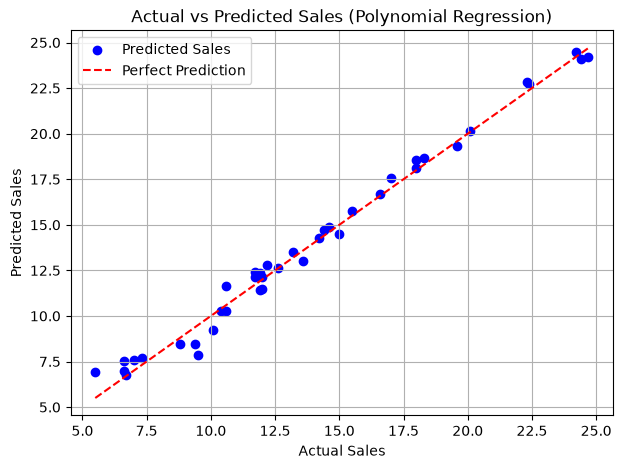

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, polynomial_predictions, color="blue",
            label="Predicted Sales")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--",
         label="Perfect Prediction")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales (Polynomial Regression)")
plt.legend()
plt.grid()
plt.show()
